# Energy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss import energy
from qss.distributions import prepare_2D_lattice_data, DistType
from tools.scientific_plot_v2 import ScientificPlotter, PlotConfig

plotter = ScientificPlotter()

## 2D Lattice

In [3]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Energy

In [4]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if not "entropy"  in mu_df.columns:
        raise ValueError("Lack of the calculated chemical potential! Please run notebook number 2")
    
    if "energy" in mu_df.columns:
        energy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        energy_df = energy(mu_df, e_k)
        energy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
energy_df

mu  iterations  converged      residual  \
distro n        k_BT     H_a                                                    
FD     0.010000 100.0000 0.0 -529.350422          23       True  1.389213e-08   
       0.035359 100.0000 0.0 -401.770608          20       True  1.965488e-08   
       0.060718 100.0000 0.0 -346.402147          22       True  8.176050e-09   
       0.086077 100.0000 0.0 -310.185144          23       True  3.017669e-08   
       0.111436 100.0000 0.0 -283.030030          18       True  1.844956e-09   
...                                  ...         ...        ...           ...   
SSL    0.897564 0.0001   0.0    2.822747          23       True  3.207925e-08   
       0.922923 0.0001   0.0    3.077741          23       True  7.584998e-07   
       0.948282 0.0001   0.0    3.369331          20       True  4.881190e-09   
       0.973641 0.0001   0.0    3.672891          20       True  2.298422e-06   
       0.999000 0.0001   0.0    3.984269          28       True  4.627269e-07   

                               entropy    energy  free_energy  
distro n        k_BT     H_a                                   
FD     0.010000 100.0000 0.0  0.062956 -0.000227    -6.295855  
       0.035359 100.0000 0.0  0.177724 -0.000792   -17.773185  
       0.060718 100.0000 0.0  0.271965 -0.001343   -27.197808  
       0.086077 100.0000 0.0  0.354951 -0.001879   -35.496971  
       0.111436 100.0000 0.0  0.430018 -0.002401   -43.004214  
...                                ...       ...          ...  
SSL    0.897564 0.0001   0.0  0.622412 -0.055385    -0.055447  
       0.922923 0.0001   0.0  0.638992 -0.000300    -0.000364  
       0.948282 0.0001   0.0  0.656659 -0.000300    -0.000366  
       0.973641 0.0001   0.0  0.674325 -0.000300    -0.000367  
       0.999000 0.0001   0.0  0.692532 -0.000300    -0.000369  

[1400 rows x 7 columns]

# Energy

#### $\frac{S} {k_B N} = f(n)$

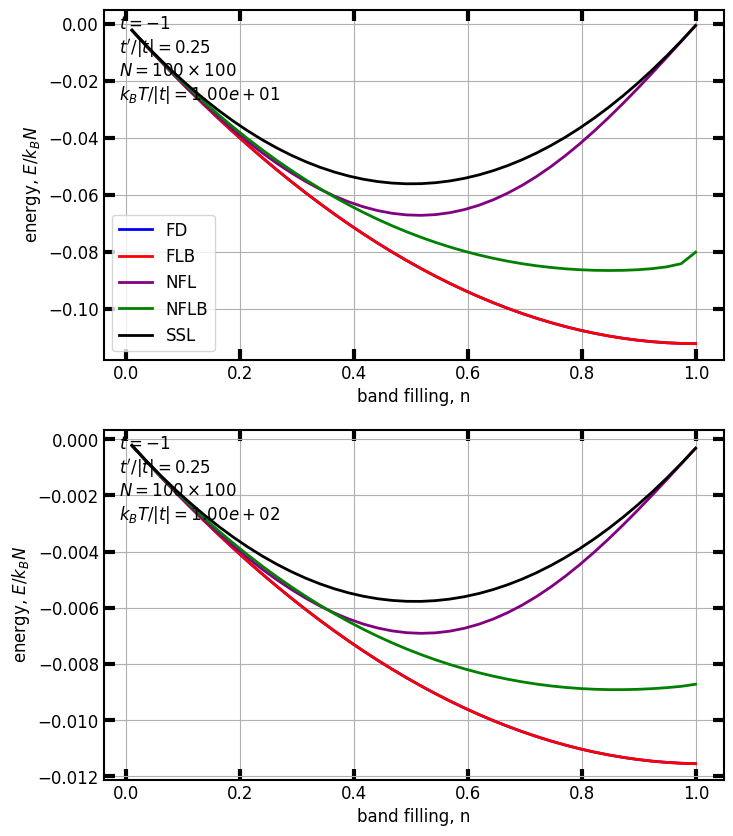

In [5]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

plotter.plot_scalar_result(
    results=energy_df,
    x_param="n",
    y_col="energy",
    y_label=r"energy, $E / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=1,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N
)
plt.show()

## Free energy

$$ \frac{F}{N |t|} =  \frac{1}{N |t|}  \sum_k \epsilon_k n_k - \frac{k_bT}{|t|} \frac{S}{k_bN}$$


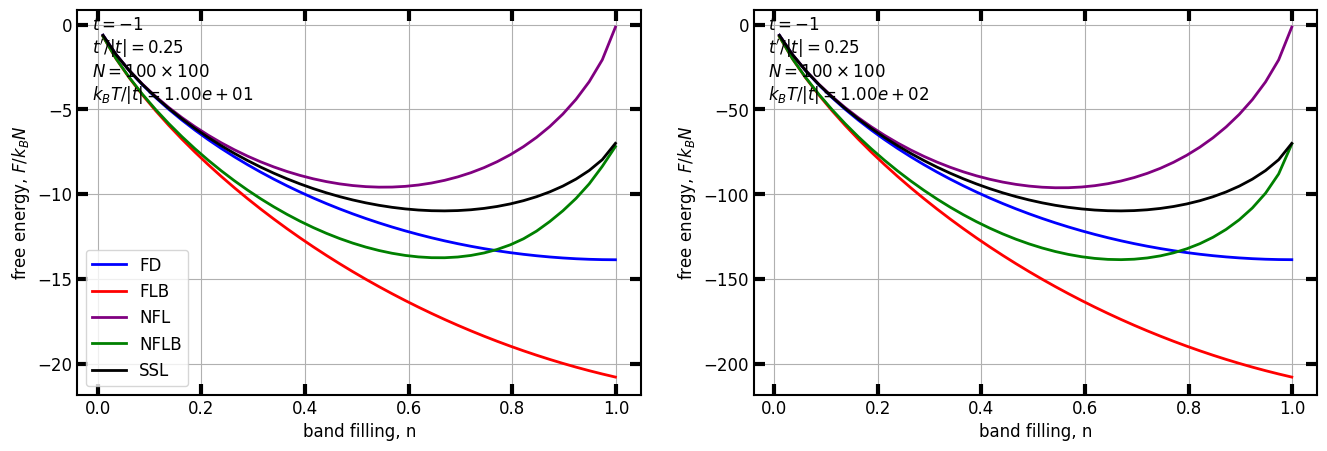

In [6]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

plotter.plot_scalar_result(
    results=energy_df,
    x_param="n",
    y_col="free_energy",
    y_label=r"free energy, $F / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=2,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N
)
plt.show()